/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1HD8kUl6AuMn0B3dZI7kRtqF9Js9OEkwd
To: /content/Task1.mp4
100% 6.07M/6.07M [00:00<00:00, 47.0MB/s]


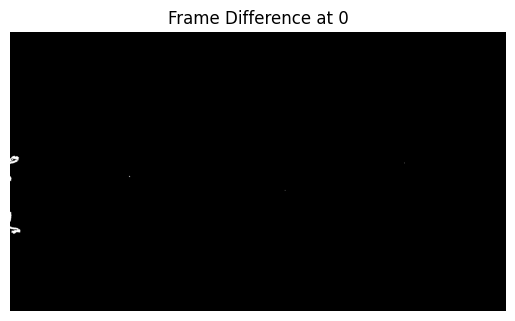

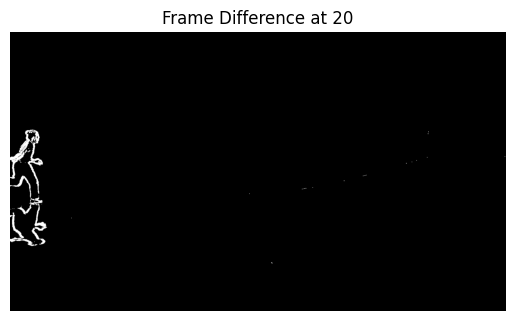

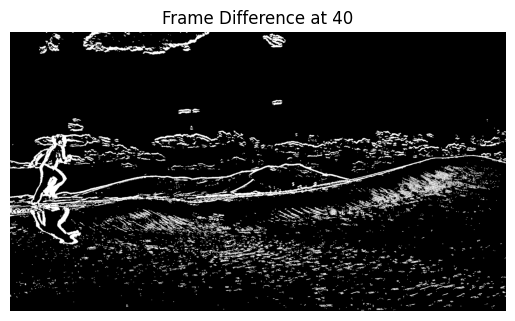

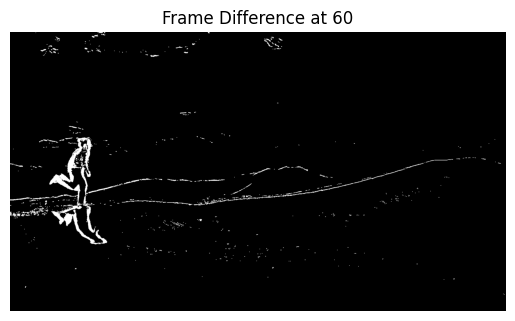

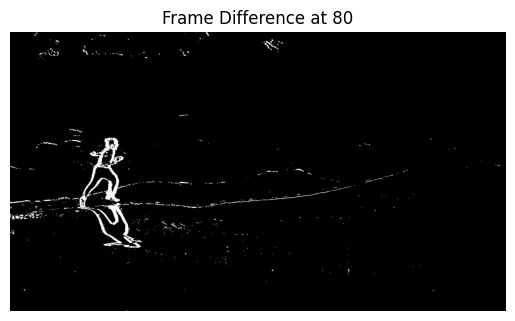

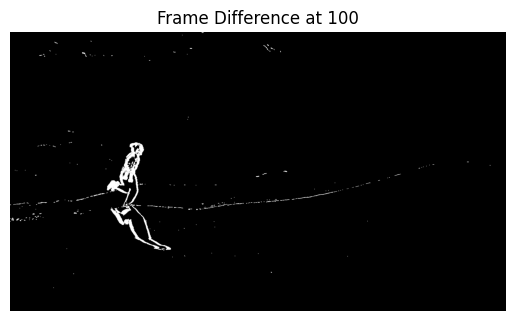

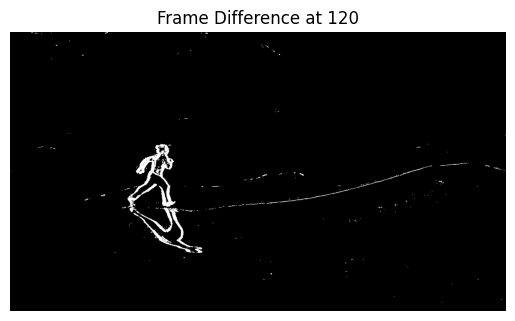

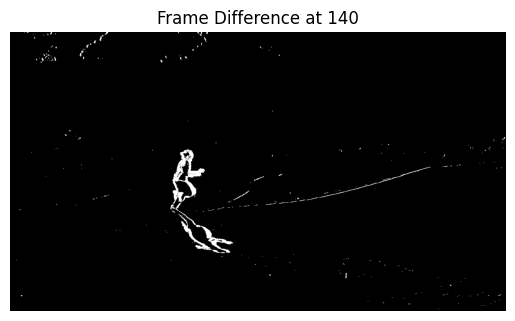

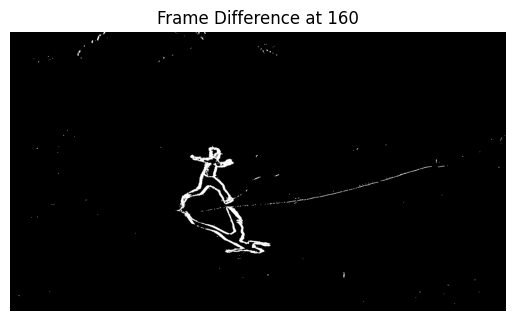

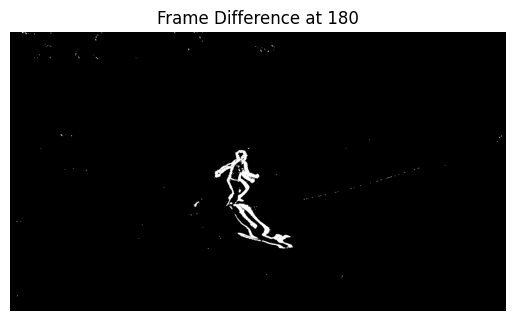

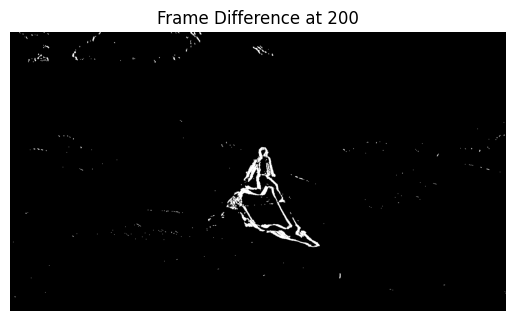

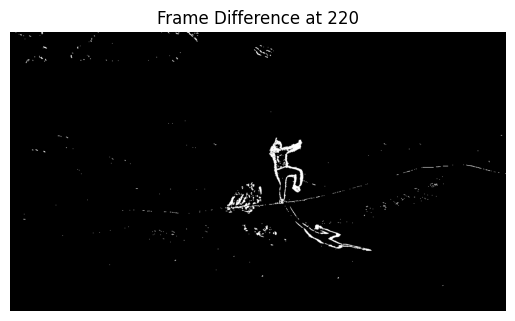

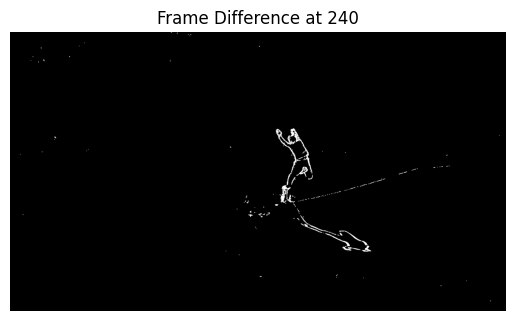

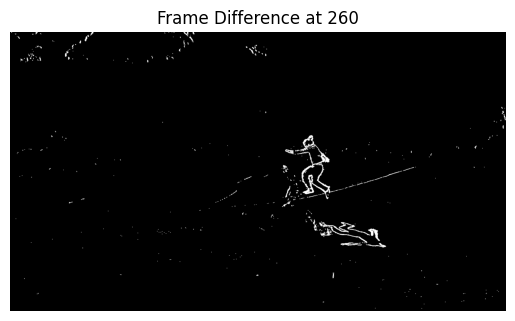

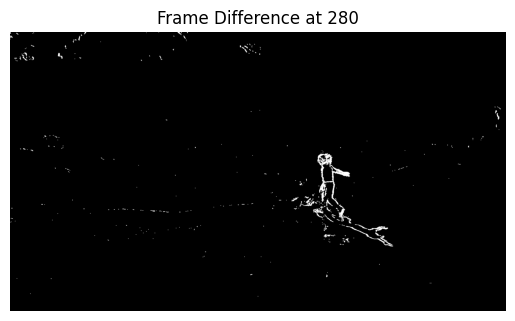

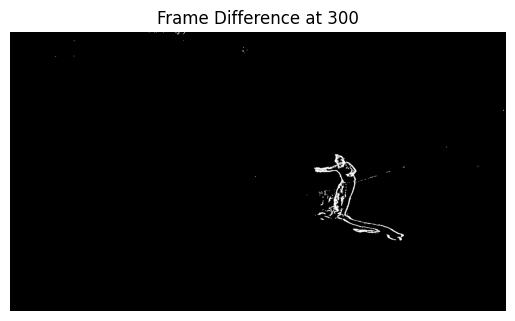

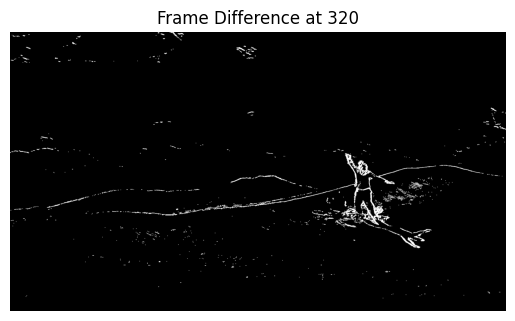

Total residual frames: 329
Saved outputs: output_gray.mp4 and output_residual.mp4


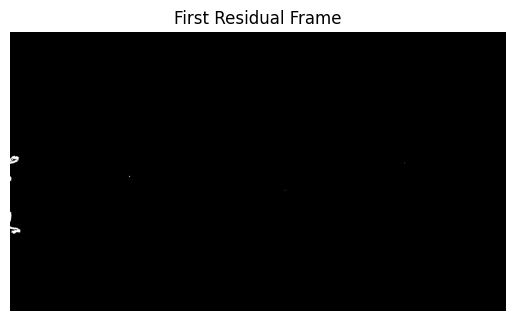

In [1]:
#task1
#task requirements:
#1. Import OpenCV library.
#2. Read consecutive frames from the input video “Task 1”.
#3. Convert the frames into Grayscale, and save it as a video file.
#4. Apply frame differencing between frames to detect moving object(s).
#(Ideally, this will leave only moving objects) In this technique, every frame is
#subtracted from the previous frame to create a residual frame.
#5. Write the residual frames (resultant frames after frame differencing) in a video
#file.


#task overview: In this task, we detect motion by subtracting consecutive grayscale frames of a video. The output highlights regions where changes occur (moving objects). Grayscale frames are saved as output_gray.mp4, and the residual frames (motion-only) are saved as output_residual.mp4. Morphological operations are applied to reduce noise, and sample frames are visualized to confirm detection.

import cv2
import matplotlib.pyplot as plt
import numpy as np
!gdown --id 1HD8kUl6AuMn0B3dZI7kRtqF9Js9OEkwd -O Task1.mp4 #get video from drive

#read video
video = "/content/Task1.mp4"
vidcap = cv2.VideoCapture(video)
#get video properties
frame_width = int(vidcap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(vidcap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = vidcap.get(cv2.CAP_PROP_FPS)

#Video writers for grayscale
gray_out = cv2.VideoWriter("output_gray.mp4",
                           cv2.VideoWriter_fourcc(*'mp4v'),
                           fps, (frame_width, frame_height), False)
#Video writers for residual
residual_out = cv2.VideoWriter("output_residual.mp4",
                               cv2.VideoWriter_fourcc(*'mp4v'),
                               fps, (frame_width, frame_height), False)

#List to store residual frames
residual_frames = []
#read the first frame
success, prev_frame = vidcap.read()

if not success:
    print("Error: could not read video")
else:
    prev_gray = cv2.cvtColor(prev_frame, cv2.COLOR_BGR2GRAY) #convert to grayscale
    gray_out.write(prev_gray)

    frame_count = 0
    while True:
        success, frame = vidcap.read() #read the first frame
        if not success: #if there are no more frames exit the loop
            break

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) #Convert current frame to grayscale
        gray_out.write(gray)

        #Frame differencing (get the absolute difference between the current and previous frame)
        diff = cv2.absdiff(prev_gray, gray)
        _, thresh = cv2.threshold(diff, 5, 255, cv2.THRESH_BINARY) #threshold to highlight the areas with moving objects
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2)) # Morphological operation to remove small noise
        clean = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)

        #save the processed residual frame
        residual_frames.append(clean)
        residual_out.write(clean)

        #preview every 20 frames
        if frame_count % 20 == 0:
            plt.imshow(clean, cmap='gray')
            plt.title(f"Frame Difference at {frame_count}")
            plt.axis("off")
            plt.show()

        prev_gray = gray
        frame_count += 1

vidcap.release()
gray_out.release()
residual_out.release()
cv2.destroyAllWindows()

print(f"Total residual frames: {len(residual_frames)}")
print("Saved outputs: output_gray.mp4 and output_residual.mp4")
#show first residual frame
if residual_frames:
    plt.imshow(residual_frames[0], cmap='gray')
    plt.title("First Residual Frame")
    plt.axis("off")
    plt.show()


/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1dACbdwWHkCdgD9nNJIEOdQOqQgWQjN4P
To: /content/Task2.mp4
100% 921k/921k [00:00<00:00, 113MB/s]
video loaded successfully


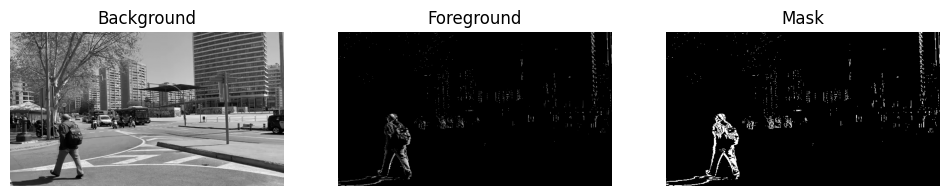

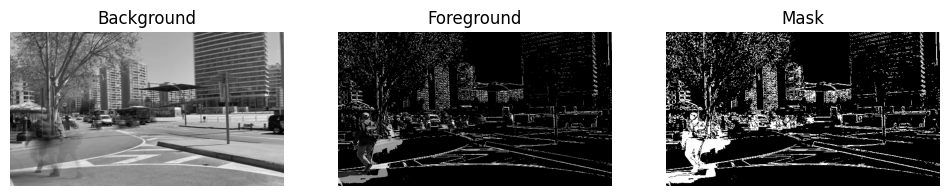

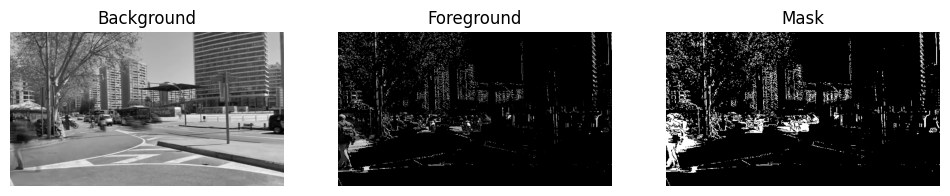

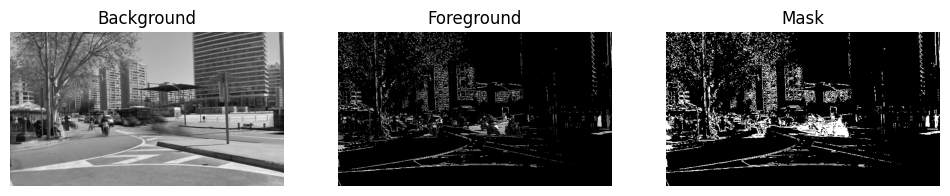

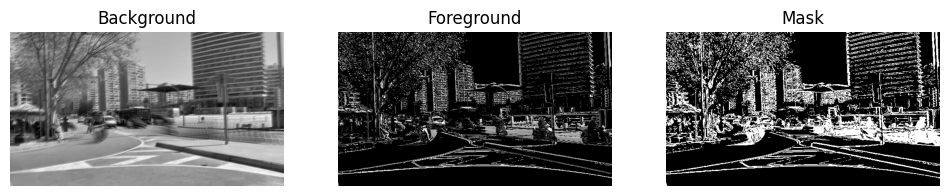

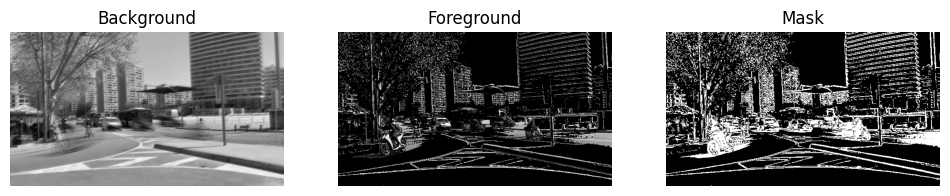

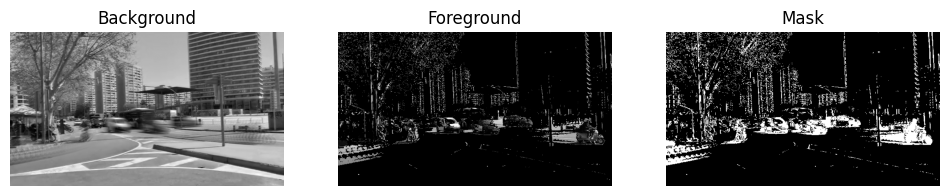

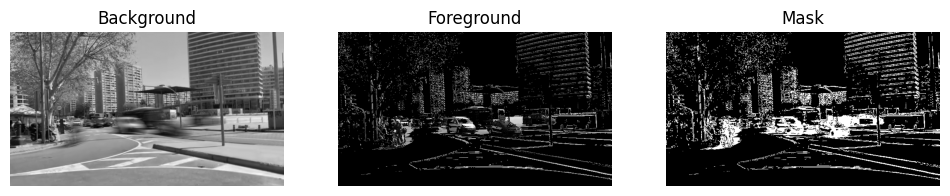

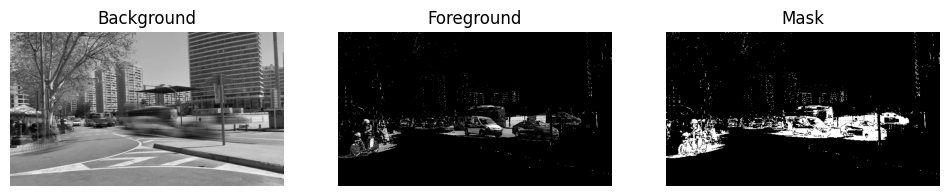

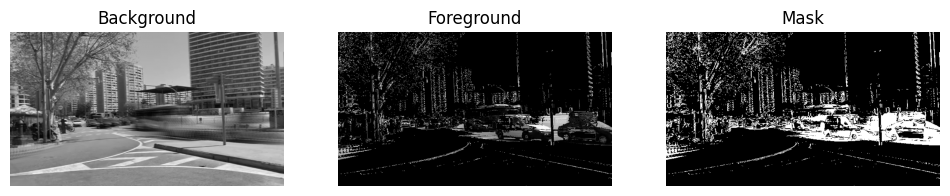

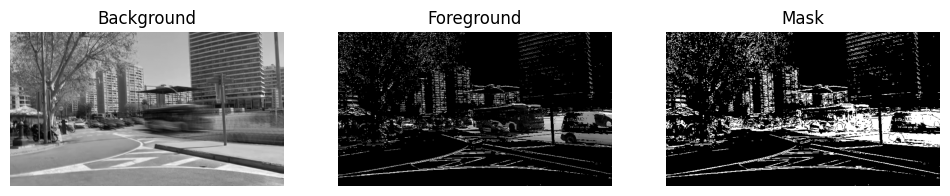

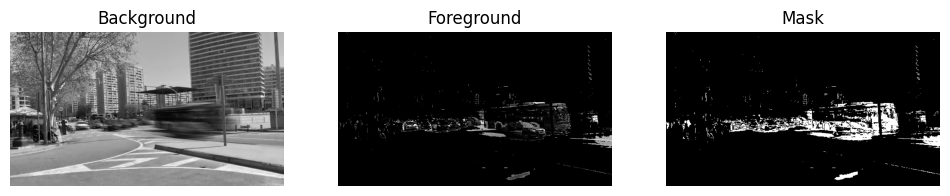

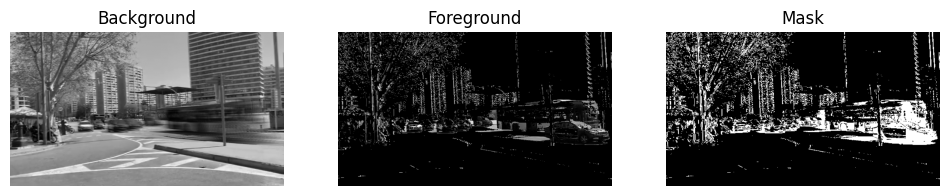

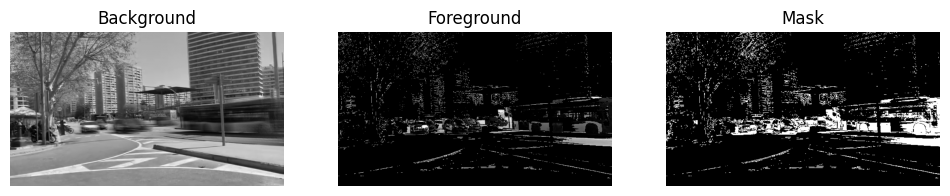

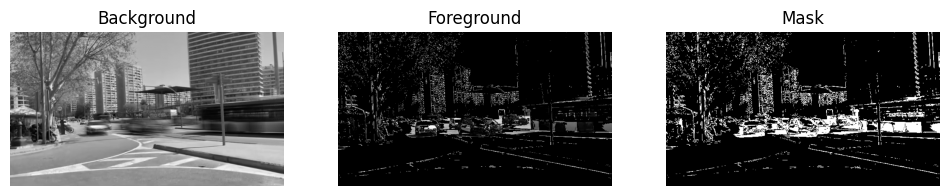

Saved 300 frames to /content/task2_output/


In [2]:
# Task 2
#task requirements:
#Import OpenCV.
#Read and process the video “Task 2”.
#Convert frames to grayscale.
#Implement a running average background model using the formula:BGt+1​=(1−β)⋅BGt​+β⋅It​
#Generate foreground images, masks, and updated background images.
#Save all outputs as .png files in separate folders.
#task overview: In this task, we build a dynamic background model using a running average to distinguish moving objects (foreground) from static background. Each new frame is compared to the current background model to produce a mask (binary moving areas), a foreground image (moving objects only), and an updated background image. These results are saved frame by frame as .png files in three separate folders: foreground/, mask/, and background/. The parameter β controls how fast the background adapts to changes.

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
!gdown --id 1dACbdwWHkCdgD9nNJIEOdQOqQgWQjN4P -O Task2.mp4

video = "/content/Task2.mp4"
cap = cv2.VideoCapture(video)
if not cap.isOpened():
    print("Error: Cannot open video")
else:
    print("video loaded successfully")

# Parameters
beta = 0.1 # background update rate
images = "/content/task2_output"
os.makedirs(images + "/foreground", exist_ok=True)
os.makedirs(images + "/mask", exist_ok=True)
os.makedirs(images + "/background", exist_ok=True)

# Read first frame (initialize BG0)
ret, frame = cap.read()
if not ret:
    print("Error: Cannot read first frame")
else:
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    BG = gray.astype("float")  #background model

frame_count = 0
#process frames
while True:
    ret, frame = cap.read()
    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) #convert to grayscale

    #Foreground mask = |It - BGt|
    diff = cv2.absdiff(gray, cv2.convertScaleAbs(BG)) #subtract background from current frame
    _, mask = cv2.threshold(diff, 25, 255, cv2.THRESH_BINARY)  # threshold to get moving objects moving obj=white background=black

    #apply mask on current frame so only moving objects will remain
    foreground = cv2.bitwise_and(gray, mask)

    #save images
    cv2.imwrite(f"{images}/foreground/frame_{frame_count:04d}.png", foreground)
    cv2.imwrite(f"{images}/mask/frame_{frame_count:04d}.png", mask)
    cv2.imwrite(f"{images}/background/frame_{frame_count:04d}.png", cv2.convertScaleAbs(BG))

    # update the background model
    BG = (1 - beta) * BG + beta * gray
    #preview every 20 frames
    if frame_count % 20 == 0:
        fig, axs = plt.subplots(1, 3, figsize=(12, 4))
        axs[0].imshow(cv2.convertScaleAbs(BG), cmap="gray")
        axs[0].set_title("Background")
        axs[0].axis("off")

        axs[1].imshow(foreground, cmap="gray")
        axs[1].set_title("Foreground")
        axs[1].axis("off")

        axs[2].imshow(mask, cmap="gray")
        axs[2].set_title("Mask")
        axs[2].axis("off")

        plt.show()

    frame_count += 1

cap.release()
cv2.destroyAllWindows()

print(f"Saved {frame_count} frames to {images}/")
